![Python Banner](../../Image/05_01_tree_based_models.png)



# 1.3 Causal Survival Forest (CSF)



## Overview

A **Causal Survival Forest** extends causal forests to handle time-to-event data — situations where the outcome is not just *what happened*, but *when* it happened, and where many subjects are right-censored (their event time was never observed). Like its parent method, a CSF estimates the **Conditional Average Treatment Effect (CATE)**, $\tau(X)$, but it does so on a survival timescale rather than a simple continuous outcome.

CSFs are particularly valuable in medicine (does this drug extend survival, and for whom?), economics (when does job training lead to re-employment?), and any setting where dropout, loss to follow-up, or end-of-study cutoffs create incomplete outcome data.

### Key Concepts

**Defining the treatment effect** on survival data requires choosing a summary measure:

*Restricted Mean Survival Time (RMST):*

$$\tau(X) = E[\min(T(1), h) - \min(T(0), h) \mid X = x]$$ This compares average survival time up to a fixed horizon $h$ between treated and control groups.

*Survival probability difference:*

$$\tau(X) = P[T(1) > h \mid X = x] - P[T(0) > h \mid X = x]$$ This compares the probability of surviving past time $h$ under treatment versus control.

**Right-censoring** means we observe $Y = \min(T, C)$ and an event indicator $D = \mathbf{1}(T \leq C)$, where $C$ is the censoring time. CSFs correct for this using **Inverse Probability of Censoring Weighting (IPCW)**, which upweights observed events to account for those that were censored.

**AIPW scores** (Augmented Inverse Probability Weighting, from Cui et al., 2023) provide doubly-robust pseudo-outcomes for each subject, combining a direct outcome model with a propensity model. These pseudo-outcomes are what the forest actually splits on, enabling unbiased CATE estimation even with censoring.

**Honest estimation** — the same safeguard as in standard causal forests — partitions data so that the subsample used to find splits is strictly separate from the subsample used to estimate effects within leaves.

### How CSFs Work

**1. Inputs** — Covariates $X$, observed time $Y$, treatment $W$, event indicator $D$, and time horizon $h$.

**2. Censoring correction** — Estimate censoring probabilities $\hat{P}(C > t \mid X)$ via a survival forest, then compute IPCW-corrected or AIPW pseudo-outcomes $\tilde{Y}_i$ for each individual.

**3. Tree construction** — Grow $B$ trees on random data/feature subsets. Each split maximizes the heterogeneity of pseudo-outcomes between child nodes, isolating subgroups with meaningfully different treatment effects.

**4. Honest leaf estimation** — A held-out subsample ($S_2$) estimates $\tau(x)$ within each leaf, preventing overfitting to the split-finding subsample ($S_1$).

**5. Aggregation and output** — Average $\tau(x)$ estimates across all $B$ trees. Final outputs: per-individual CATE $\hat{\tau}(x)$, population ATE, confidence intervals, and covariate importance.


![Causal survival forest](../../Image/cuasal_survival_forest.png)



The key addition relative to a standard causal forest is **steps 2 and 3** — the censoring correction and pseudo-outcome construction. These are what make CSF handle survival data correctly. Without IPCW, censored subjects would introduce bias; without AIPW pseudo-outcomes, the forest would have nothing meaningful to split on.

The **choice of** $\tau(X)$ definition (RMST vs. survival probability) should be made based on the scientific question: RMST gives a time-scale interpretation ("this drug adds X months of survival for patients like you"), while the survival probability difference is more directly interpretable clinically ("this increases your chance of surviving 5 years by X%").

The **honest estimation** in step 4 mirrors what standard causal forests do but applied to the pseudo-outcomes from step 3 — it ensures the same data isn't used to both carve the covariate space and measure effects within it.

### How does it differ from Causal Forest and Survival Forest?

| **Aspect** | **Survival Forest** | **Causal Forest** | **Causal Survival Forest** |
|-----------------|-------------------|------------------|------------------|
| `Objective` | Predict survival probability or hazard over time | Estimate heterogeneous treatment effects | Estimate treatment effects on survival outcomes |
| `Outcome Type` | Time-to-event (censored) | Continuous or binary | Time-to-event (censored) |
| `Treatment Variable` | None | Required (W: 0/1) | Required (W: 0/1) |
| `Inputs` | X, Y, D | X, Y, W | X, Y, D, W |
| `Output` | Survival curves or hazard functions | Treatment effect estimates $\tau(X)$ | Treatment effect on survival $\tau(X)$ |
| `Use Case` | Survival prediction (e.g., patient prognosis) | Treatment effect heterogeneity (e.g., drug impact) | Treatment effect on survival (e.g., therapy impact) |
| `Assumptions` | Handles censoring | Unconfoundedness, overlap | Unconfoundedness, overlap, censoring handled |
| Python estimator | Predictive survival model | `CausalForest` | `CausalSurvivalForest` |

### Practical Notes

-   `Survival Forest`: Used when the goal is purely predictive (e.g., forecasting patient survival based on covariates). It does not involve a treatment variable.

-   `Causal Forest`: Used for non-survival outcomes (e.g., blood pressure, test scores) to understand how treatment effects vary across individuals.

-   `Causal Survival Forest`: Used when both treatment effects and survival outcomes are of interest, combining the strengths of the other two models.




## Causal Survival Forest (CSF) in Python

This tutorial uses `CausalSurvivalForest` from PyCausalML to estimate Conditional Average Treatment Effects (CATE) on a survival timescale.

We'll cover:

-   Getting started with a causal survival forest
-   A use case built from `Data/patients.csv`


## Setup

This notebook fits **`CausalSurvivalForest`** from **[PyCausalML](https://github.com/zia207/PyCausalML)** (`pycausalml.tree_based_models`).

`fit(X, treatment, time, event)` returns the fitted estimator. `predict` returns a NumPy array of conditional average treatment effects. A fitted model also exposes `explain` and `plot_shap`.

Install the package from this repository, with the plotting and boosting extras.

The patient example is built with `make_patient_survival` from `causal_tree_methods.py` in this folder.


In [1]:
import subprocess
import sys
from pathlib import Path

def _repo_root() -> Path:
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "pyproject.toml").is_file() and (cand / "src" / "pycausalml").is_dir():
            return cand
    raise FileNotFoundError(
        "PyCausalML repository was not found. Run this notebook from the repository."
    )

root = _repo_root()
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q", "-e", f"{root}[plot,boost,shap]", "statsmodels",
])
print("PyCausalML ready.")


PyCausalML ready.


In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from pycausalml import (
    CausalSurvivalForest,
)

from pycausalml.tree_based_models import (
    best_linear_projection,
    rank_average_treatment_effect,
)

import sys
from pathlib import Path

def _add_methods_path():
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        for rel in (
            Path("causal_tree_methods.py"),
            Path("Tutorials") / "05_01_Tree_Based_Models" / "causal_tree_methods.py",
            Path("Notebook") / "05_01_Tree_Based_Models" / "causal_tree_methods.py",
        ):
            path = cand / rel
            if path.is_file():
                sys.path.insert(0, str(path.parent))
                return
    raise FileNotFoundError("causal_tree_methods.py was not found")

_add_methods_path()
from causal_tree_methods import (
    make_patient_survival,
)

def find_repo_root(start=None) -> Path:
    here = Path(start or Path.cwd()).resolve()
    for cand in [here, *here.parents]:
        if (cand / "Data").is_dir() and (cand / "Image").is_dir():
            return cand
    raise FileNotFoundError("Could not find a folder containing Data/ and Image/.")

def data_path(filename: str) -> Path:
    return find_repo_root() / "Data" / filename

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
print("Imported PyCausalML")


Imported PyCausalML


## Use case

The runnable example is built from `Data/patients.csv`: age, comorbidity, baseline risk, and sex are the covariates, and treatment, failure time, and censoring are simulated on top of those covariates so the restricted-mean effect is identified.

This section uses `CausalSurvivalForest` to estimate Conditional Average Treatment Effects (CATE) on Restricted Mean Survival Time (RMST). Below, we prepare the patient cohort, train the forest, and show predictions.

### Data and Data Preparation


In [3]:
surv = make_patient_survival(n=3000, horizon=24, random_state=1)
X, Y, W, D = surv["X"], surv["Y"], surv["W"], surv["D"]
horizon = surv["horizon"]
feature_names = surv["feature_names"]
print("n =", len(Y), "event rate", round(D.mean(), 3), "horizon", horizon)
print(pd.Series(W).value_counts())


n = 3000 event rate 0.758 horizon 24.0
1    1503
0    1497
Name: count, dtype: int64


### Fit CSF

In [4]:
cs_forest = CausalSurvivalForest(horizon=horizon, num_trees=80, min_node_size=8, random_state=1)
cs_forest.fit(X, W, Y, D, feature_names=feature_names)
print("Fitted causal survival forest")


Fitted causal survival forest


### Predicting & Evaluating on Simulated Data

#### Predict on New Test Data

In [5]:
X_test = np.zeros((10, X.shape[1]))
X_test[:, 0] = np.linspace(-1.5, 1.5, 10)
X_test[:, 2] = np.linspace(-1.5, 1.5, 10)
cs_pred = cs_forest.predict(X_test)
print(pd.DataFrame({"rmst_effect": cs_pred}))


   rmst_effect
0    21.958110
1   -42.278300
2    -3.221770
3     2.856728
4    -5.148984
5    -0.578396
6     5.706142
7     2.957663
8     4.039365
9     8.604780


#### Predictions on the training sample

In [6]:
cs_in = cs_forest.predict(X)
print(pd.Series(cs_in).describe().round(3))


count    3000.000
mean        3.441
std        15.588
min       -96.602
25%        -0.852
50%         4.209
75%         9.756
max       122.872
dtype: float64


#### Predict with Confidence Intervals

In [7]:
mean, se = cs_forest.forest_.predict_interval(X_test)
table = pd.DataFrame({
    "prediction": mean,
    "std_err": se,
    "ci_low": mean - 1.96 * se,
    "ci_high": mean + 1.96 * se,
})
print(table.round(3))


   prediction  std_err  ci_low  ci_high
0      21.958    9.386   3.561   40.355
1     -42.278    9.818 -61.521  -23.036
2      -3.222    5.507 -14.015    7.571
3       2.857    3.026  -3.075    8.788
4      -5.149    2.265  -9.589   -0.709
5      -0.578    2.371  -5.226    4.069
6       5.706    1.481   2.804    8.608
7       2.958    1.118   0.766    5.149
8       4.039    1.198   1.691    6.388
9       8.605    1.190   6.271   10.938


#### Estimate Average Treatment Effect (ATE)

In [8]:
print(cs_forest.average_treatment_effect())


{'estimate': 3.548605980394607, 'std.err': 1.8322265440406802}


#### Best Linear Projection of CATE

In [9]:
blp = best_linear_projection(cs_forest.dr_scores_, X[:, 0])
print(pd.DataFrame({
    "term": ["intercept", "age_z"],
    "estimate": blp["params"],
    "std_err": blp["bse"],
    "p_value": blp["pvalues"],
}).round(3))


        term  estimate  std_err  p_value
0  intercept     3.549    1.832    0.053
1      age_z     1.493    2.080    0.473


#### Assess Treatment Effect Heterogeneity

AUTOC: -3.916


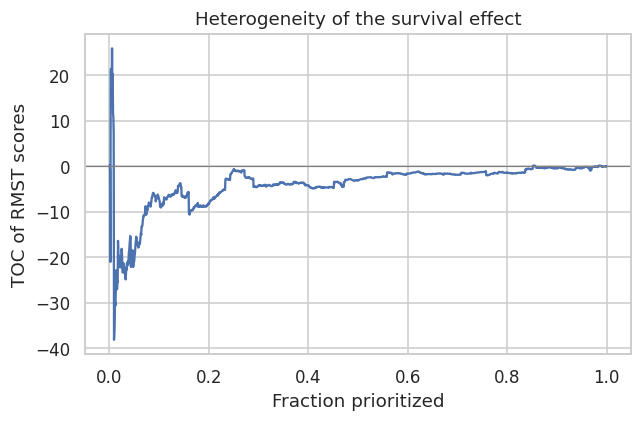

In [10]:
rng = np.random.default_rng(1)
n = len(Y)
train = rng.choice(n, size=n // 2, replace=False)
eval_idx = np.setdiff1d(np.arange(n), train)
train_forest = CausalSurvivalForest(horizon=horizon, num_trees=60, min_node_size=8, random_state=2)
eval_forest = CausalSurvivalForest(horizon=horizon, num_trees=60, min_node_size=8, random_state=3)
train_forest.fit(X[train], W[train], Y[train], D[train], feature_names=feature_names)
eval_forest.fit(X[eval_idx], W[eval_idx], Y[eval_idx], D[eval_idx], feature_names=feature_names)
rate = rank_average_treatment_effect(
    eval_forest.dr_scores_, train_forest.predict(X[eval_idx])
)
print("AUTOC:", round(rate["autoc"], 3))
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(rate["q"], rate["toc"], color="#4C72B0")
ax.axhline(0, color="gray", lw=0.8)
ax.set_xlabel("Fraction prioritized")
ax.set_ylabel("TOC of RMST scores")
ax.set_title("Heterogeneity of the survival effect")
fig.tight_layout()
plt.show()


### SHAP values for the CATE

`explain()` attributes the predicted treatment effects $\hat{\tau}(X)$ to covariates. A subsample of the training rows is used so the explanation stays fast.

In [11]:
sv = cs_forest.explain(X, max_samples=40, random_state=2026)
print(sv.values.shape)


(40, 4)


#### SHAP importance

Mean absolute SHAP value shows which covariates move the predicted treatment effect the most. The waterfall under it decomposes one training row.

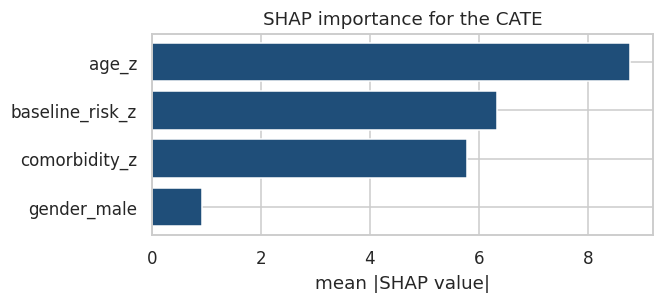

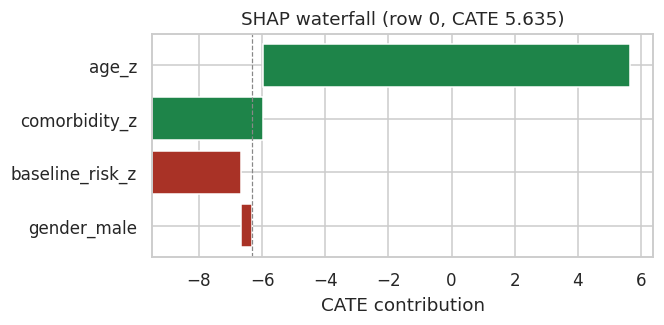

In [12]:
sv.plot_importance()
plt.show()
sv.plot_waterfall(row=0)
plt.show()


#### SHAP Dependence Plots (main effects)

Explore how individual covariates modify the estimated treatment effect.

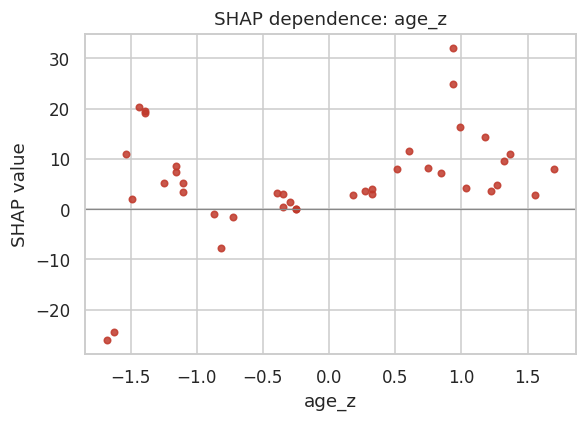

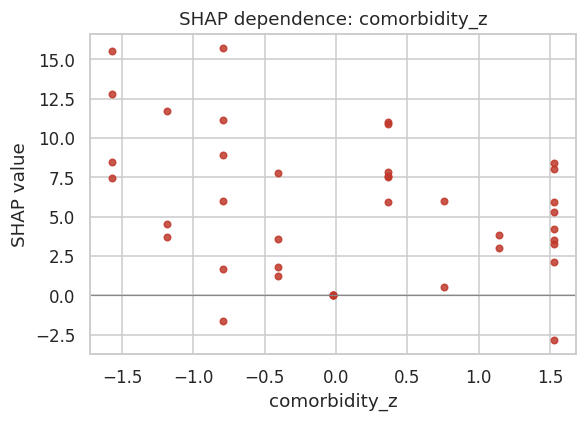

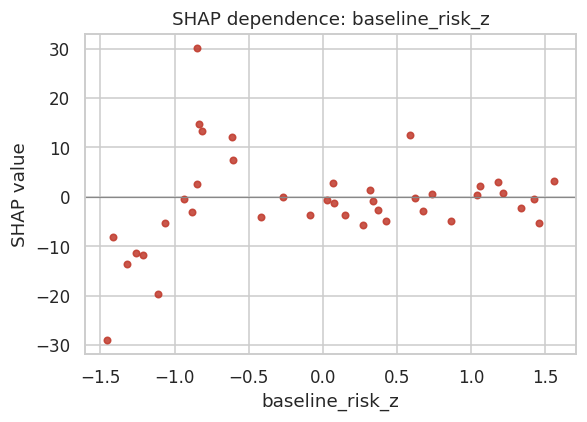

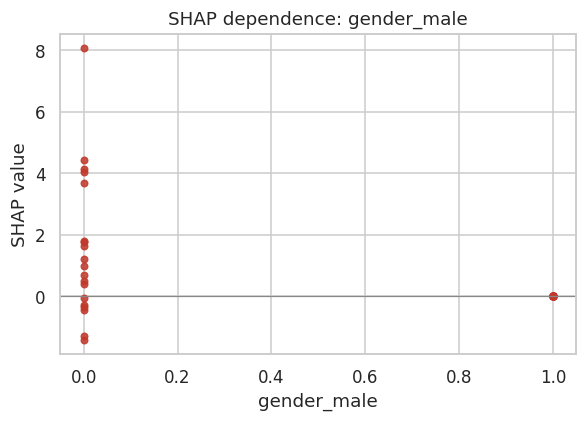

In [13]:
for name in feature_names:
    sv.plot_dependence(name)
    plt.show()


The same dependence plot for baseline risk alone:

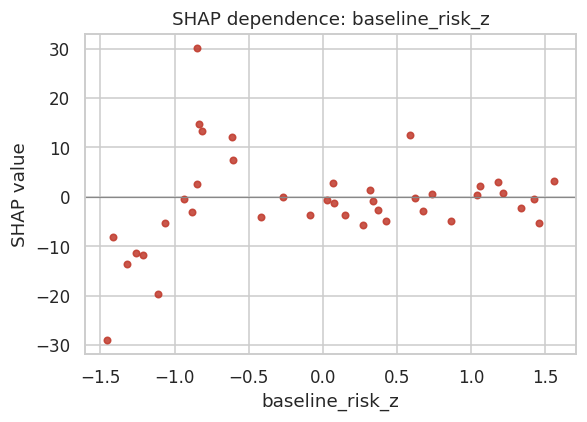

In [14]:
sv.plot_dependence("baseline_risk_z")
plt.show()


#### Waterfall plot for a single observation

The row with the largest predicted treatment benefit shows how each covariate contributes to that CATE.

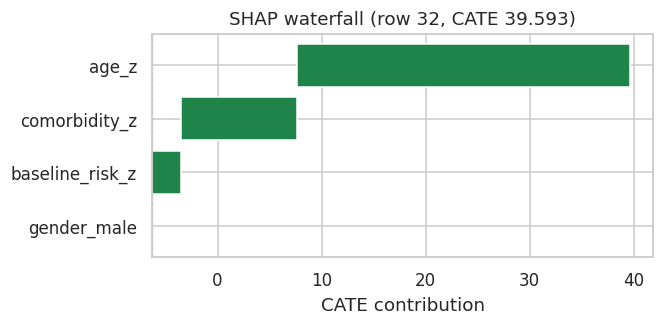

In [15]:
row_id = int(np.argmax(sv.predictions))
sv.plot_waterfall(row=row_id)
plt.show()


#### Optional: Explain a few test set observations

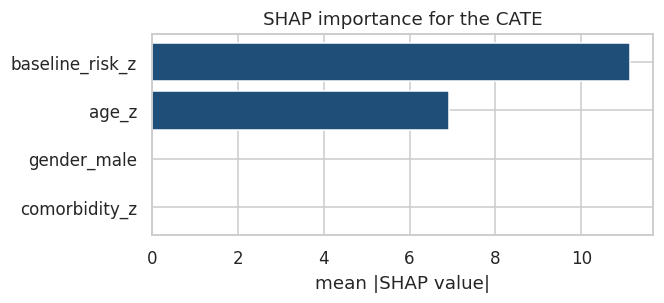

In [16]:
sv_test = cs_forest.explain(X_test, max_samples=10, random_state=4)
sv_test.plot_importance()
plt.show()


### Interpretation Notes

-   **Positive SHAP** means the feature value pushes the predicted treatment effect (RMST gain) **up**.
-   **Negative SHAP** pushes the predicted treatment effect **down**.
-   These values explain **heterogeneity** (variation in $\hat{\tau}(X)$), not the survival time itself.
-   Dependence plots show how a covariate's contribution changes as that covariate changes.
-   Compare SHAP values from `explain()` with `feature_importance()`. SHAP decomposes each prediction; forest importance summarizes how often a covariate is used for splits.
-   `explain()` applies directly to the fitted survival forest.

## Summary and Conclusion

This notebook demonstrated `CausalSurvivalForest` from PyCausalML. Covariates come from `Data/patients.csv`, with treatment, failure time, and censoring simulated so the restricted-mean effect is identified. We defined a time horizon for RMST and fit the forest to estimate heterogeneous treatment effects while accounting for right-censoring. The forest provides non-parametric CATE estimates, variable importance, and a summary of heterogeneity. For methodology and theory, see Cui et al. (2023).

## Resources

1.  **Cui, Y., Kosorok, M. R., Sverdrup, E., Wager, S., & Zhu, R. (2023).** Estimating heterogeneous treatment effects with right-censored data via causal survival forests. *Journal of the Royal Statistical Society: Series B (Statistical Methodology)*, **85**(2), 179–211.\
    <https://academic.oup.com/jrsssb/article/85/2/179/7058918>

2.  [Causal survival forests preprint](https://arxiv.org/abs/2006.09639)
